## Сравнение моделей

In [16]:
import sys
import os
sys.path.append(os.path.abspath('..'))

In [17]:
from sklearn.pipeline import Pipeline
import pandas as pd
from src.transformers import DataCleaner, NaNCatboostImputer
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import f1_score, make_scorer
from sklearn.linear_model import LogisticRegression
from src.utils import show_metrics
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import json
from pathlib import Path
import optuna
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer

In [18]:
df = pd.read_csv('../data/raw/train.csv')
X = df.drop('Credit Default', axis=1)
y = df['Credit Default']

## Пайплайн препроцессинга

In [19]:
ohe_step = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                drop="first",
                sparse_output=False,
                handle_unknown="ignore",
                dtype=int, 
            ),
            ["Home Ownership", "Purpose", "Term"],
        ),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

In [20]:
preprocessor = Pipeline(steps=[
    ('data_cleaner', DataCleaner()),
    ('one_hot_encoder', ohe_step),
    ('yicj_imputer', NaNCatboostImputer('Years in current job', 'classification')),
    ('bankruptcies_imputer', NaNCatboostImputer('Bankruptcies', 'classification')),
    ('credit_score_imputer', NaNCatboostImputer('Credit Score', 'regression')),
    ('annual_income_imputer', NaNCatboostImputer('Annual Income', 'regression'))
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

c:\Users\kstat\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


## Baseline (позже)

## Логистическая регрессия

Точность (accuracy)  = 0.7859555555555555
Точность (precision) = 0.7935702199661591
Полнота (recall)     = 0.30238555770470665
f1_score             = 0.43790849673202614
roc_auc_score = 0.7810459750578198


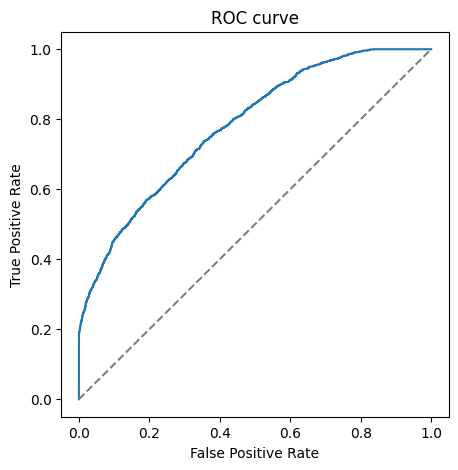

Точность (accuracy)  = 0.7733333333333333
Точность (precision) = 0.8186046511627907
Полнота (recall)     = 0.31316725978647686
f1_score             = 0.45302445302445304
roc_auc_score = 0.7753765384750902


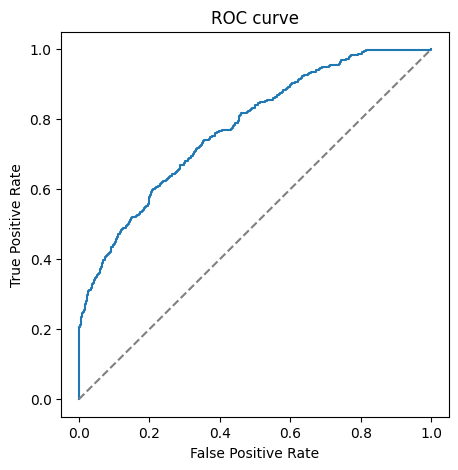

In [21]:
log_reg_pipeline = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('log_reg', LogisticRegression())
])
log_reg_pipeline.fit(X_train, y_train)
y_train_pred_log_reg = log_reg_pipeline.predict(X_train)
y_train_proba_log_reg = log_reg_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_log_reg = log_reg_pipeline.predict(X_test)
y_test_proba_log_reg = log_reg_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_log_reg, y_train_proba_log_reg)
show_metrics(y_test, y_test_pred_log_reg, y_test_proba_log_reg)

Решающее дерево

Точность (accuracy)  = 0.7112888888888889
Точность (precision) = 0.4849732400164677
Полнота (recall)     = 0.7595099935525468
f1_score             = 0.5919597989949749
roc_auc_score = 0.8088173433643933


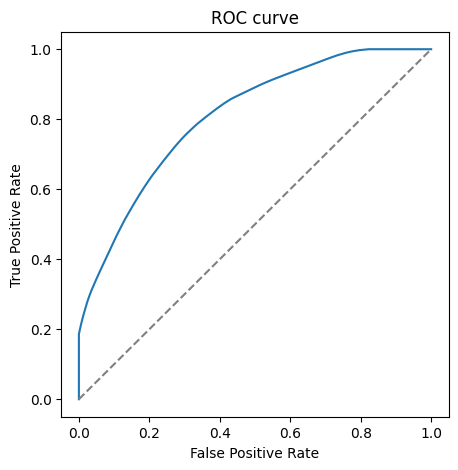

Точность (accuracy)  = 0.6554666666666666
Точность (precision) = 0.4505882352941176
Полнота (recall)     = 0.6814946619217082
f1_score             = 0.5424929178470255
roc_auc_score = 0.7359941510165251


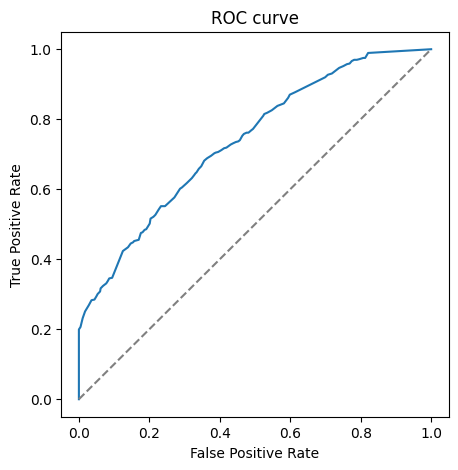

In [22]:
dt_pipeline = Pipeline(steps=[
    ('DecisionTree', DecisionTreeClassifier())
])

project_root = Path.cwd().parent
config_path = project_root / 'configs' / 'model_config.json'
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "DecisionTree"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "DecisionTree__max_depth": optuna.distributions.IntDistribution(1, 150),
            "DecisionTree__min_samples_split": optuna.distributions.IntDistribution(2, 100),
            "DecisionTree__min_samples_leaf": optuna.distributions.IntDistribution(1, 50),
            "DecisionTree__max_features": optuna.distributions.CategoricalDistribution([None, 'sqrt', 'log2']),
            "DecisionTree__random_state": optuna.distributions.IntDistribution(42, 42),
            "DecisionTree__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced', 'balanced_subsample'])      
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                dt_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("DecisionTree__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "DecisionTree",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

dt_pipeline.set_params(**{f"DecisionTree__{k}": v for k, v in best_params_.items()})
dt_pipeline.fit(X_train, y_train)
y_train_pred_dt = dt_pipeline.predict(X_train)
y_train_proba_dt = dt_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_dt = dt_pipeline.predict(X_test)
y_test_proba_dt = dt_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_dt, y_train_proba_dt)
show_metrics(y_test, y_test_pred_dt, y_test_proba_dt)

## Случайный лес

Точность (accuracy)  = 0.7875555555555556
Точность (precision) = 0.5849236641221374
Полнота (recall)     = 0.7904577691811734
f1_score             = 0.672333424732657
roc_auc_score = 0.8762669783727033


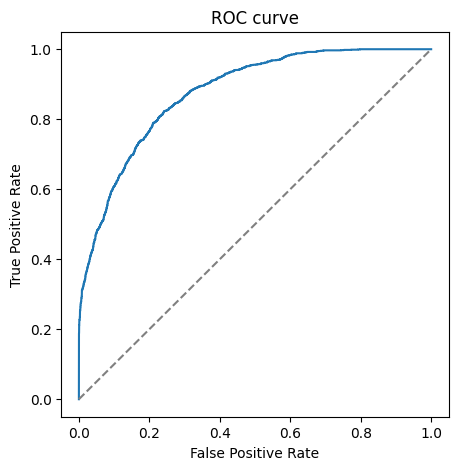

Точность (accuracy)  = 0.6928
Точность (precision) = 0.4903314917127072
Полнота (recall)     = 0.6316725978647687
f1_score             = 0.552099533437014
roc_auc_score = 0.7619507091689186


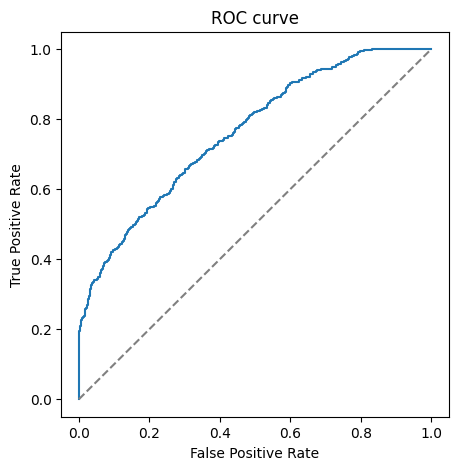

In [23]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "RandomForest"), None)
best_params_ = model_info["params"] if model_info else None
rf_pipeline = Pipeline(steps=[
    ('RandomForest', RandomForestClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "RandomForest__max_depth": optuna.distributions.IntDistribution(1, 30),
            "RandomForest__min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "RandomForest__min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "RandomForest__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "RandomForest__n_estimators": optuna.distributions.IntDistribution(20, 500),
            "RandomForest__random_state": optuna.distributions.IntDistribution(42, 42),  
            "RandomForest__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced', 'balanced_subsample'])     
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                rf_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("RandomForest__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "RandomForest",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

rf_pipeline.set_params(**{f"RandomForest__{k}": v for k, v in best_params_.items()})
rf_pipeline.fit(X_train, y_train)
y_train_pred_rf = rf_pipeline.predict(X_train)
y_train_proba_rf = rf_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_rf = rf_pipeline.predict(X_test)
y_test_proba_rf = rf_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_rf, y_train_proba_rf)
show_metrics(y_test, y_test_pred_rf, y_test_proba_rf)

## Градиентный бустинг

Точность (accuracy)  = 0.9994666666666666
Точность (precision) = 1.0
Полнота (recall)     = 0.9980657640232108
f1_score             = 0.9990319457889641
roc_auc_score = 1.0


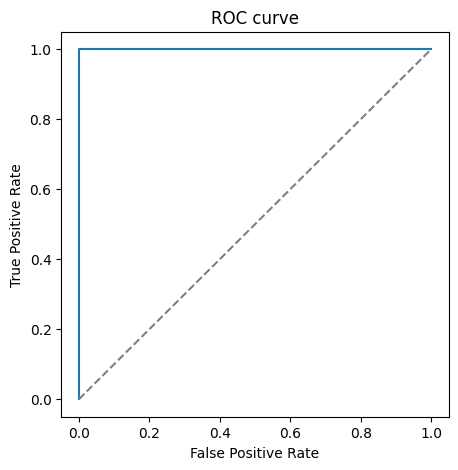

Точность (accuracy)  = 0.7424
Точность (precision) = 0.6053333333333333
Полнота (recall)     = 0.40391459074733094
f1_score             = 0.48452508004268946
roc_auc_score = 0.7275696362409304


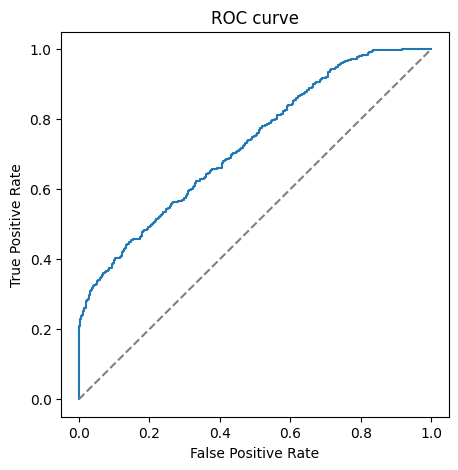

In [24]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

gb_pipeline = Pipeline(steps=[
    ('GradientBoosting', GradientBoostingClassifier())
])

model_info = next((p for p in configs if p["model_name"] == "GradientBoosting"), None)
best_params_ = model_info["params"] if model_info else None

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "GradientBoosting__max_depth": optuna.distributions.IntDistribution(1, 10),
            "GradientBoosting__min_samples_split": optuna.distributions.IntDistribution(2, 50),
            "GradientBoosting__min_samples_leaf": optuna.distributions.IntDistribution(5, 50),
            "GradientBoosting__max_features": optuna.distributions.CategoricalDistribution(['sqrt', 'log2']),
            "GradientBoosting__n_estimators": optuna.distributions.IntDistribution(20, 1500, log=True),
            "GradientBoosting__learning_rate": optuna.distributions.FloatDistribution(1e-5, 0.5, log=True),
            "GradientBoosting__random_state": optuna.distributions.IntDistribution(42, 42)     
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                gb_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("GradientBoosting__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "GradientBoosting",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

gb_pipeline.set_params(**{f"GradientBoosting__{k}": v for k, v in best_params_.items()})
gb_pipeline.fit(X_train, y_train)
y_train_pred_gb = gb_pipeline.predict(X_train)
y_train_proba_gb = gb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_gb = gb_pipeline.predict(X_test)
y_test_proba_gb = gb_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_gb, y_train_proba_gb)
show_metrics(y_test, y_test_pred_gb, y_test_proba_gb)

## CatBoost

Точность (accuracy)  = 0.8008888888888889
Точность (precision) = 0.6148108684070325
Полнота (recall)     = 0.7440361057382334
f1_score             = 0.6732788798133023
roc_auc_score = 0.8765399743684456


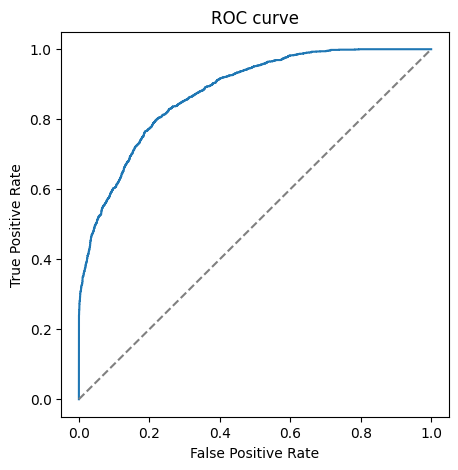

Точность (accuracy)  = 0.6938666666666666
Точность (precision) = 0.49085365853658536
Полнота (recall)     = 0.5729537366548043
f1_score             = 0.5287356321839081
roc_auc_score = 0.7639523191300789


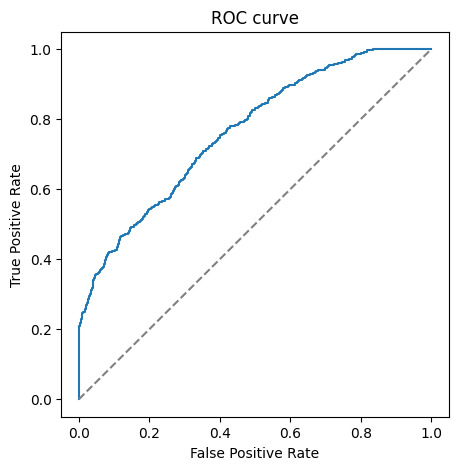

In [25]:
frozen_params = {
     'silent':True,
     'random_state':42
}
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "CatBoost"), None)
best_params_ = model_info["params"] if model_info else None
cb_pipeline = Pipeline(steps=[
    ('CatBoost', CatBoostClassifier(**frozen_params))
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "CatBoost__depth": optuna.distributions.IntDistribution(2, 10),
            "CatBoost__l2_leaf_reg": optuna.distributions.FloatDistribution(1e-2, 15, log=True),
            "CatBoost__iterations": optuna.distributions.IntDistribution(20, 1500, log=True),
            "CatBoost__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.5, log=True),
            "CatBoost__random_strength": optuna.distributions.FloatDistribution(1e-2, 1),
            "CatBoost__auto_class_weights": optuna.distributions.CategoricalDistribution(['None', 'Balanced', 'SqrtBalanced'])     
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                cb_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("CatBoost__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "CatBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

cb_pipeline.set_params(**{f"CatBoost__{k}": v for k, v in best_params_.items()})
cb_pipeline.fit(X_train, y_train)
y_train_pred_cb = cb_pipeline.predict(X_train)
y_train_proba_cb = cb_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_cb = cb_pipeline.predict(X_test)
y_test_proba_cb = cb_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_cb, y_train_proba_cb)
show_metrics(y_test, y_test_pred_cb, y_test_proba_cb)

## XGBoost

Точность (accuracy)  = 0.8332444444444445
Точность (precision) = 0.9181446111869032
Полнота (recall)     = 0.4339136041263701
f1_score             = 0.5893169877408057
roc_auc_score = 0.8985861814332969


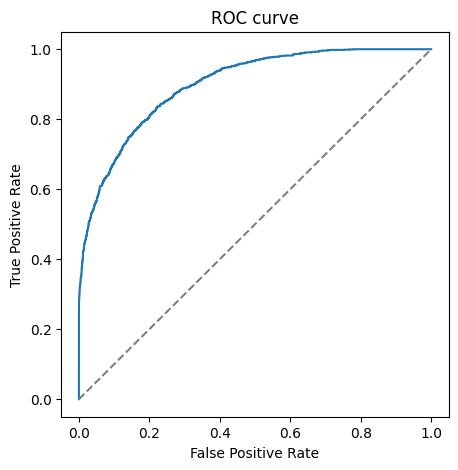

Точность (accuracy)  = 0.7696
Точность (precision) = 0.751937984496124
Полнота (recall)     = 0.34519572953736655
f1_score             = 0.47317073170731705
roc_auc_score = 0.7634685176702722


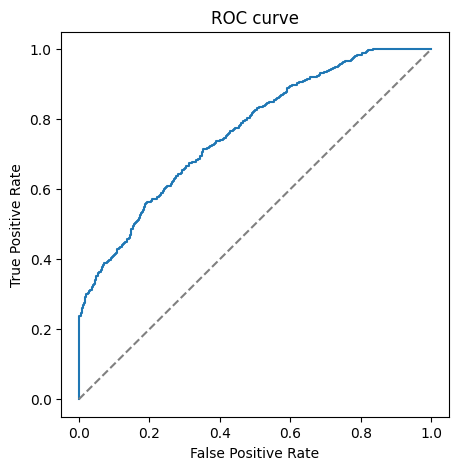

In [26]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "XGBoost"), None)
best_params_ = model_info["params"] if model_info else None
xg_pipeline = Pipeline(steps=[
    ('XGBoost', XGBClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "XGBoost__n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "XGBoost__max_depth": optuna.distributions.IntDistribution(2, 10),
            "XGBoost__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "XGBoost__reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "XGBoost__random_state": optuna.distributions.IntDistribution(42, 42)    
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                xg_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("XGBoost__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "XGBoost",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

xg_pipeline.set_params(**{f"XGBoost__{k}": v for k, v in best_params_.items()})
xg_pipeline.fit(X_train, y_train)
y_train_pred_xg = xg_pipeline.predict(X_train)
y_train_proba_xg = xg_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_xg = xg_pipeline.predict(X_test)
y_test_proba_xg = xg_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_xg, y_train_proba_xg)
show_metrics(y_test, y_test_pred_xg, y_test_proba_xg)

## LightGBM

[LightGBM] [Warning] min_data_in_leaf is set=87, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=87
[LightGBM] [Warning] feature_fraction is set=0.5621466274778248, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.5621466274778248
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Warning] min_data_in_leaf is set=87, min_child_samples=20 will be ignored. Current value: min_data_in_leaf=87
[LightGBM] [Warning] feature_fraction is set=0.5621466274778248, colsample_bytree=1.0 will be ignored. Current value: feature_fraction=0.5621466274778248
[LightGBM] [Info] Number of positive: 1551, number of negative: 4074
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000829 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1956
[LightGBM] [Info] Number of data points in the train set: 5625, number of used features: 27
[LightGBM] 

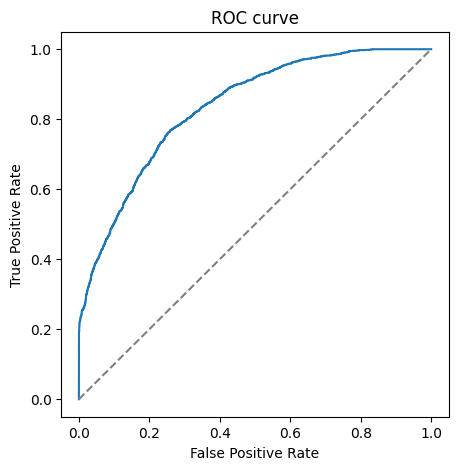

Точность (accuracy)  = 0.688
Точность (precision) = 0.4844384303112314
Полнота (recall)     = 0.6370106761565836
f1_score             = 0.5503458877786318
roc_auc_score = 0.7603786932210879


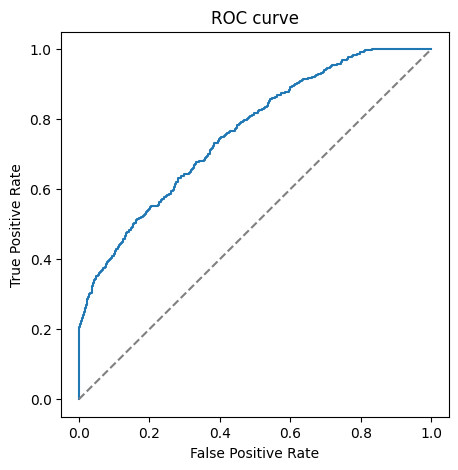

In [27]:
if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as config:
        configs = json.load(config)
else:
    configs = []

model_info = next((p for p in configs if p["model_name"] == "LightGBM"), None)
best_params_ = model_info["params"] if model_info else None
lgbm_pipeline = Pipeline(steps=[
    ('LightGBM', LGBMClassifier())
])

if best_params_ is None:
    f1 = make_scorer(f1_score)
    param_grid = {
            "LightGBM__n_estimators": optuna.distributions.IntDistribution(50, 1000, log=True),
            "LightGBM__max_depth": optuna.distributions.IntDistribution(2, 15),
            "LightGBM__learning_rate": optuna.distributions.FloatDistribution(1e-3, 0.1, log=True),
            "LightGBM__reg_lambda": optuna.distributions.FloatDistribution(1e-2, 10),
            "LightGBM__num_leaves": optuna.distributions.IntDistribution(7, 255),
            "LightGBM__min_data_in_leaf": optuna.distributions.IntDistribution(20, 100),
            "LightGBM__subsample": optuna.distributions.FloatDistribution(0.8, 1),
            "LightGBM__feature_fraction": optuna.distributions.FloatDistribution(0.3, 1),
            "LightGBM__random_state": optuna.distributions.IntDistribution(42, 42),
            "LightGBM__class_weight": optuna.distributions.CategoricalDistribution([None, 'balanced'])
        }

    cv = KFold(n_splits=5, random_state=42, shuffle=True)

    optuna_search = optuna.integration.OptunaSearchCV(
                lgbm_pipeline,
                param_grid,
                cv=cv,
                n_trials=50,
                scoring=f1,
                random_state=42
            )

    optuna_search.fit(X_train, y_train)
    best_params_ = {
        k.replace("LightGBM__", ""): v
        for k, v in optuna_search.best_params_.items()
    }

    model_info = {
                "model_name": "LightGBM",
                "params": best_params_
            }

    configs.append(model_info)

    with open(config_path, "w", encoding="utf-8") as config:
        json.dump(configs, config, indent=4, ensure_ascii=False)

lgbm_pipeline.set_params(**{f"LightGBM__{k}": v for k, v in best_params_.items()})
lgbm_pipeline.fit(X_train, y_train)
y_train_pred_lgbm = lgbm_pipeline.predict(X_train)
y_train_proba_lgbm = lgbm_pipeline.predict_proba(X_train)[:, 1]

y_test_pred_lgbm = lgbm_pipeline.predict(X_test)
y_test_proba_lgbm = lgbm_pipeline.predict_proba(X_test)[:, 1]

show_metrics(y_train, y_train_pred_lgbm, y_train_proba_lgbm)
show_metrics(y_test, y_test_pred_lgbm, y_test_proba_lgbm)